# 03 — Partie B : modèles utilisés sans entraînement

### Démonstration : qu'est-ce que le NLI ?
Un modèle de **NLI** (*Natural Language Inference*) reçoit deux phrases, une **prémisse** et une **hypothèse**, et dit si l'hypothèse découle de la prémisse :
**implication** (*entailment*), **neutre**, ou **contradiction**.

Attention : ici « prémisse » est un terme du NLI (la phrase de départ). Il ne faut pas le confondre avec la colonne `premise` de nos arguments.

In [1]:
import gc
import pandas as pd
import torch
from valeval.data import load_split, VALUES
from valeval.zeroshot import MODELES, charger, classes, probas_nli, score_implication

paires = [
    ("A man is playing a guitar on stage.", "A person is making music."),
    ("A man is playing a guitar on stage.", "The man is famous."),
    ("A man is playing a guitar on stage.", "The man is asleep."),
]
tab = pd.DataFrame({"hypothèse": [b for _, b in paires], "attendu": ["implication", "neutre", "contradiction"]})
for nom in MODELES:
    tok, modele = charger(nom)
    p = probas_nli(tok, modele, [a for a, _ in paires], [b for _, b in paires])
    tab[f"P(implication) {nom}"] = p[:, classes(modele)["entailment"]].astype(float).round(3)
    del modele; gc.collect(); torch.cuda.empty_cache()
tab

C:\Users\ayoub\Documents\BDIO\S3\Llms\Tp2_v2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1030 22:07:41.754000 61204 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 5/202 [00:00<00:11, 17.72it/s]

Loading weights:  61%|██████    | 123/202 [00:00<00:00, 407.96it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 421.05it/s]

... (19 outputs left out)

Loading weights:  85%|████████▌ | 335/394 [00:00<00:00, 500.22it/s]

Loading weights:  99%|█████████▉| 391/394 [00:00<00:00, 517.07it/s]

Loading weights: 100%|██████████| 394/394 [00:00<00:00, 473.83it/s]

,hypothèse,attendu,P(implication) mdeberta,P(implication) bart,P(implication) deberta_large
0,A person is making music.,implication,0.039,0.996,0.994
1,The man is famous.,neutre,0.001,0.000,0.001
2,The man is asleep.,contradiction,0.003,0.000,0.000


**Lecture :** trois phrases ne suffisent pas à juger un modèle, mais ce test est utile : mDeBERTa ne reconnaît pas l'implication évidente (P ≈ 0,04), alors que les modèles anglais la trouvent.
Ce n'est pas un bug d'installation : la tokenisation est identique à celle du fichier d'origine `spm.model`, et les résultats sont les mêmes en float16 et float32.

**Choix de modèles :** on garde les deux modèles imposés et on ajoute `deberta_large`, conçu pour le zero-shot. Les comparaisons se feront sur val.
mDeBERTa reste indispensable pour les hypothèses en français : c'est le seul modèle multilingue des trois.

### L'astuce zero-shot
Le modèle n'a jamais vu nos 20 valeurs. On transforme donc la classification en NLI : l'**argument** devient la prémisse, et une **phrase décrivant la valeur** devient l'hypothèse.
Si le modèle juge que l'argument « implique » cette phrase, on répond oui.

Essai sur quelques arguments du train, avec 5 hypothèses écrites à la main :

In [2]:
tok, modele = charger("deberta_large")
train = load_split("training")
exemples = train.iloc[[0, 1, 2]]
textes = (exemples.conclusion + " . " + exemples.stance + " . " + exemples.premise).tolist()
hyps = {"Security: societal": "This argument is about keeping society safe and stable.",
        "Security: personal": "This argument is about personal health and safety.",
        "Power: dominance": "This argument is about having power over others.",
        "Hedonism": "This argument is about pleasure and enjoying life.",
        "Tradition": "This argument is about respecting traditions and religion."}
s = score_implication(tok, modele, textes, list(hyps.values()))
tab = pd.DataFrame(s, columns=list(hyps), index=exemples.id).round(2)
tab["vraies valeurs"] = [[v for v in VALUES if r[v]] for _, r in exemples.iterrows()]
tab

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

Loading weights:  12%|█▏        | 47/394 [00:00<00:00, 453.45it/s]

Loading weights:  24%|██▎       | 93/394 [00:00<00:00, 424.67it/s]

Loading weights:  35%|███▍      | 136/394 [00:00<00:00, 423.45it/s]

Loading weights:  45%|████▌     | 179/394 [00:00<00:00, 356.71it/s]

Loading weights:  61%|██████▏   | 242/394 [00:00<00:00, 424.83it/s]

Loading weights:  73%|███████▎  | 286/394 [00:00<00:00, 423.42it/s]

Loading weights:  84%|████████▍ | 330/394 [00:00<00:00, 423.44it/s]

Loading weights:  95%|█████████▍| 373/394 [00:00<00:00, 401.26it/s]

Loading weights: 100%|██████████| 394/394 [00:00<00:00, 414.01it/s]

,Security: societal,Security: personal,Power: dominance,Hedonism,Tradition,vraies valeurs
id,,,,,,
A01002,0.01,0.00,0.01,0.0,0.0,[Security: societal]
A01005,0.00,0.54,0.01,0.0,0.0,[Security: personal]
A01006,0.00,0.00,0.05,0.0,0.0,"[Power: dominance, Security: societal]"


### B1 : zero-shot sur val
3 modèles × 3 formulations × 20 valeurs × 1 896 arguments (`scripts/run_zeroshot.py`, scores dans `cache/`).
Aucun entraînement, mais le(s) seuil(s) sont choisis sur val. Les scores étant parfois écrasés près de 0, on cherche le seuil dans une grille de quantiles.
Comme en Partie A, on donne aussi un score **honnête** par validation croisée sur les sujets de val.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold
from valeval.data import label_matrix
from valeval.evaluate import scores, f1_par_valeur, seuil_unique, seuils_par_valeur, grille_quantiles, log_result
from valeval.hypotheses import FORMULATIONS

val = load_split("validation")
y_va = label_matrix(val)
probas = {(m, f): np.load(f"../cache/zs_{m}_{f}_validation.npy") for m in MODELES for f in FORMULATIONS}

def croise(p):
    """Scores honnêtes : seuils réglés sur 4/5 des sujets, mesurés sur le 1/5 restant."""
    unique, valeur = np.zeros_like(y_va), np.zeros_like(y_va)
    for a, b in GroupKFold(5).split(p, groups=val.conclusion):
        unique[b] = p[b] >= seuil_unique(y_va[a], p[a], grille_quantiles(p[a]))
        valeur[b] = p[b] >= seuils_par_valeur(y_va[a], p[a], quantiles=True)
    return scores(y_va, unique)["macro_f1"], scores(y_va, valeur)["macro_f1"]

lignes = []
for (m, f), p in probas.items():
    s = seuil_unique(y_va, p, grille_quantiles(p))
    hon_u, hon_v = croise(p)
    lignes.append({"modèle": m, "formulation": f, "seuil 0,5": scores(y_va, p >= .5)["macro_f1"],
                   "seuil unique": scores(y_va, p >= s)["macro_f1"], "valeur du seuil": s,
                   "croisé unique": hon_u, "croisé par valeur": hon_v,
                   "PR-AUC moyenne": average_precision_score(y_va, p, average="macro")})
    log_result(f"B1_zeroshot_{m}", f"hypothèses {f}", 0, val=scores(y_va, p >= s), temps_s=0, params=0,
               notes=f"seuil unique {s:.4f}, croisé par valeur {hon_v:.3f}")
b1 = pd.DataFrame(lignes)
b1.round(3)

,modèle,formulation,"seuil 0,5",seuil unique,valeur du seuil,croisé unique,croisé par valeur,PR-AUC moyenne
0,mdeberta,en,0.253,0.285,0.013,0.284,0.318,0.276
1,mdeberta,fr,0.250,0.272,0.000,0.272,0.314,0.268
2,mdeberta,reformulation,0.256,0.278,0.006,0.277,0.306,0.245
3,bart,en,0.323,0.339,0.188,0.338,0.364,0.342
4,bart,fr,0.311,0.312,0.481,0.307,0.325,0.290
5,bart,reformulation,0.296,0.312,0.301,0.308,0.348,0.295
6,deberta_large,en,0.082,0.391,0.001,0.386,0.407,0.398
7,deberta_large,fr,0.108,0.373,0.004,0.370,0.405,0.390
8,deberta_large,reformulation,0.155,0.355,0.007,0.353,0.398,0.378


**PR-AUC** : mesure à quel point les vrais positifs sont classés en haut, **sans choisir de seuil**. Elle sépare la qualité du classement du réglage du seuil.

### Quelles valeurs le NLI reconnaît-il ? (Q4)

Meilleure combinaison : ('deberta_large', 'en')


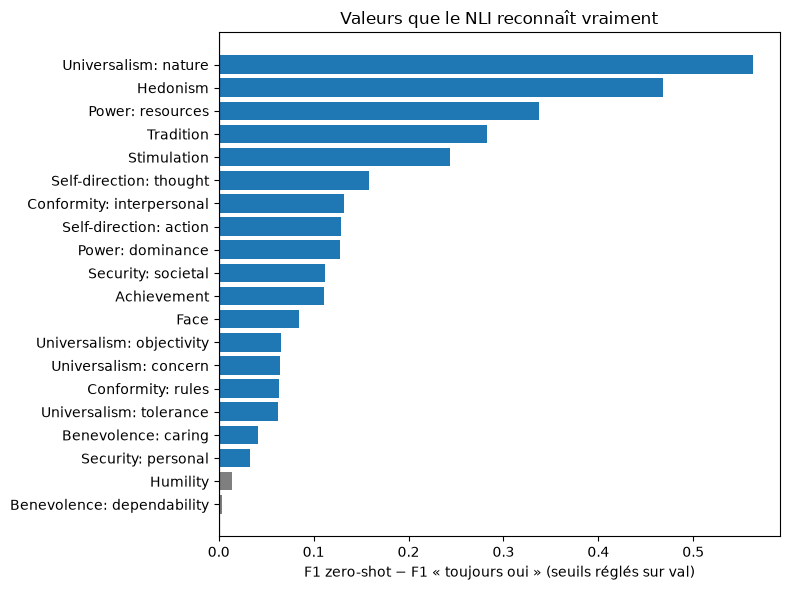

,F1 zero-shot,F1 toujours oui,PR-AUC,% dans val,gain
Universalism: nature,0.689,0.126,0.650,6.698,0.563
Hedonism,0.571,0.103,0.535,5.432,0.468
Power: resources,0.467,0.130,0.354,6.962,0.337
Tradition,0.449,0.166,0.490,9.072,0.283
Stimulation,0.379,0.136,0.302,7.278,0.244
Self-direction: thought,0.392,0.234,0.397,13.238,0.158
Conformity: interpersonal,0.194,0.061,0.092,3.165,0.132
Self-direction: action,0.543,0.415,0.616,26.160,0.129
Power: dominance,0.287,0.159,0.211,8.650,0.128
Security: societal,0.522,0.409,0.523,25.738,0.112


In [4]:
ligne = b1.sort_values("croisé par valeur", ascending=False).iloc[0]
meilleur = (ligne["modèle"], ligne["formulation"])
p = probas[meilleur]
print("Meilleure combinaison :", meilleur)
sv = seuils_par_valeur(y_va, p, quantiles=True)
parv = pd.DataFrame({"F1 zero-shot": pd.Series(f1_par_valeur(y_va, p >= sv)),
                     "F1 toujours oui": pd.Series(f1_par_valeur(y_va, np.ones_like(y_va))),
                     "PR-AUC": pd.Series(dict(zip(VALUES, average_precision_score(y_va, p, average=None)))),
                     "% dans val": pd.Series(dict(zip(VALUES, y_va.mean(0) * 100)))})
parv["gain"] = parv["F1 zero-shot"] - parv["F1 toujours oui"]
parv = parv.sort_values("gain", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(parv.index, parv.gain, color=["tab:blue" if g > .02 else "tab:gray" for g in parv.gain])
ax.axvline(0, color="black", lw=.8); ax.invert_yaxis()
ax.set(xlabel="F1 zero-shot − F1 « toujours oui » (seuils réglés sur val)",
       title="Valeurs que le NLI reconnaît vraiment")
plt.tight_layout(); plt.savefig("../figures/B1_gain_par_valeur.png", dpi=120); plt.show()
parv.round(3)

**Lecture (Q4) :**
- **Meilleure combinaison :** `deberta_large` + hypothèses anglaises, macro-F1 honnête **0,407**, sans aucun entraînement sur nos données (seuls les seuils sont réglés sur val). C'est du même ordre que la baseline entraînée (0,394) ; la différence n'est pas testée ici.
- **Modèles imposés :** BART atteint 0,364 ; mDeBERTa reste à 0,318. Avec les hypothèses françaises et un seuil unique, mDeBERTa vaut 0,272 : son seuil tombe à 0, il répond « oui » partout et égale le plancher « toutes les valeurs ». Notre choix d'un modèle anglais spécialisé est donc justifié par les chiffres.
- **Seuil :** à 0,5, `deberta_large` ne vaut que 0,082 ; son meilleur seuil unique est ~0,001. Le seuil par valeur apporte ici un vrai gain en validation croisée (0,386 → 0,407), contrairement à la baseline : chaque hypothèse produit des scores à une échelle différente.
- **Sensibilité à la description :** 0,407 (description) contre 0,398 (reformulation) pour `deberta_large`, 0,364 contre 0,348 pour BART.
- **Sensibilité à la langue :** forte pour BART (0,364 → 0,325), faible pour `deberta_large` (0,407 → 0,405), alors que ces deux modèles sont anglais.
- **Valeurs bien reconnues :** *Universalism: nature*, *Hedonism*, *Power: resources*, *Tradition*. **Presque jamais :** *Benevolence: dependability* (gain 0,003) et *Humility* (gain 0,014).